# Dice + Size — ScribblePrompt em 256² com scribbles positivos

**Objetivo:** medir o efeito do **L_size** (marcador pequeno) sozinho, sobre o Dice puro (`base_dice`). Peso 0,1: a proporção da tese (λ_size/λ_seg = 3/30); com ele o termo vale de ~0,03 (marcador = miolo) a ~0,1 (marcador = núcleo inteiro), contra ~0,2 da perda de Dice convergida. O oráculo indica que marcadores menores pioram o Dice com o ScribblePrompt; este experimento mede quanto.
Tudo o mais é igual ao `base_dice`.

| Item | Valor |
|---|---|
| Perdas | soft Dice + Size (0,1) |
| Rede final | ScribblePrompt-UNet congelado, modo `positive` (canal positivo `relu(s − τ)/(1 − τ)`, τ = 0,5; negativo zero), entrada 256² |
| MarkerUNet | U-Net (smp), encoder ResNet34 ImageNet, entrada RGBA (alpha = máscara do Cellpose) |
| Treino | Adam lr 1e-4, batch 4, *grad clip* 1,0, *cosine schedule*, aumentação rot90 + flips sorteada a cada época |
| Protocolo | validação cruzada em 5 *folds* nas 37 imagens de treino (até 200 épocas, parada após 20 validações sem melhora do Dice) → treino final com as 37 pelo número de épocas da mediana das melhores épocas → **uma** avaliação nas 14 imagens de teste |
| Linha de base | Cellpose sozinho, nas mesmas imagens |

**Saída:** `docs/estudo/resultados/dice_size/` (configuração e procedência, métricas por imagem dos *folds* e do teste, curvas
e resumo com a comparação pareada com o Cellpose). No Colab, a última célula baixa a pasta compactada.

Use um ambiente com **GPU**. Na GPU, o resultado pode variar um pouco entre execuções (operações não determinísticas do cuDNN).

## 0. Setup

In [1]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/Pedro-io/cell-fuzzy-seg.git"
BRANCH = "homolog"


def find_repo_root(start="."):
    p = os.path.abspath(start)
    prev = None
    while p != prev:
        if os.path.isdir(os.path.join(p, "src")) and os.path.exists(os.path.join(p, "pyproject.toml")):
            return p
        prev, p = p, os.path.dirname(p)
    return None


if "google.colab" in sys.modules:
    repo_root = os.path.join("/content", "cell-fuzzy-seg")
    if os.path.exists(repo_root):
        subprocess.run(["git", "-C", repo_root, "fetch", "origin", BRANCH], check=True)
        subprocess.run(["git", "-C", repo_root, "checkout", BRANCH], check=True)
        subprocess.run(["git", "-C", repo_root, "pull", "--ff-only", "origin", BRANCH], check=True)
    else:
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, repo_root], check=True)
else:
    repo_root = find_repo_root(os.getcwd())
    if repo_root is None:
        raise RuntimeError("Raiz do repositório não encontrada a partir do diretório atual.")

os.chdir(repo_root)
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)
print("Repositório:", repo_root)
print(subprocess.run(["git", "log", "-1", "--oneline"], capture_output=True, text=True).stdout.strip())

Repositório: /content/cell-fuzzy-seg
4f1779a feat(experimentos): figura do teste e experimentos de combinação de perdas


In [2]:
if "google.colab" in sys.modules:
    get_ipython().system("python -m pip install -r requirements.txt -q")
else:
    print("Ambiente local: verifique se as dependências do requirements.txt estão instaladas.")

## 1. Configuração

In [3]:
import json

import matplotlib.pyplot as plt
import numpy as np
import torch

from src.data.load.preprocessed_dataset import load_preprocessed
from src.evaluation.metrics import binary_metrics
from src.evaluation.report import save_run, summarize
from src.losses.loss_composer import LossComposer
from src.losses.terms import DiceTerm, SizeTerm
from src.models.configs.marker_unet_config import UNET_CONFIG
from src.models.networks.final_segmentation.scribble_prompting_network import ScribblePromptingNetwork
from src.models.networks.marker_unet import MarkerUNet
from src.pipeline.steps.inference.frozen_segmentation_step import FrozenSegmentationStep
from src.pipeline.steps.inference.marker_step import MarkerStep
from src.pipeline.training_pipeline import TrainingPipeline
from src.training.kfold import TrainConfig, final_epochs, run_final, run_kfold

EXPERIMENT_NAME = "dice_size"
OVERWRITE = False            # save_run recusa gravar por cima de um resultado existente

RGBA_ALPHA = "mask"          # 4º canal da MarkerUNet: máscara do Cellpose ("prob": probabilidade)
SP_INPUT_SIZE = (256, 256)   # entrada do ScribblePrompt
TAU = 0.5                    # limiar do canal positivo
MODELS_DIR = os.path.expanduser(os.path.join("~", "cell-fuzzy-models"))

CONFIG = TrainConfig(
    k=5, batch_size=4, max_epochs=200, patience=20, min_delta=0.0,
    lr=1e-4, grad_clip=1.0, threshold=0.5, seed=42, log_every=10,
)
DESCRIPTION = {
    "perdas": "soft Dice (1,0) + Size (0,1)",
    "rede_final": f"ScribblePrompt-UNet v1 congelado, scribble_mode=positive, tau={TAU}, input_size={SP_INPUT_SIZE}",
    "marker_net": "MarkerUNet (smp Unet, resnet34 ImageNet, 4 canais)",
    "rgba_alpha": RGBA_ALPHA,
    "aumentacao": "rot90 + flips, sorteada a cada época",
}

assert torch.cuda.is_available() or "google.colab" not in sys.modules, "No Colab, use um ambiente com GPU."
print("Device:", CONFIG.device)
print(json.dumps(DESCRIPTION, indent=2, ensure_ascii=False))

Device: cuda
{
  "perdas": "soft Dice (1,0) + Size (0,1)",
  "rede_final": "ScribblePrompt-UNet v1 congelado, scribble_mode=positive, tau=0.5, input_size=(256, 256)",
  "marker_net": "MarkerUNet (smp Unet, resnet34 ImageNet, 4 canais)",
  "rgba_alpha": "mask",
  "aumentacao": "rot90 + flips, sorteada a cada época"
}


## 2. Dados e linha de base do Cellpose

In [4]:
train_samples = load_preprocessed("train", alpha=RGBA_ALPHA)
test_samples = load_preprocessed("test", alpha=RGBA_ALPHA)
TRAIN_IDS = sorted(train_samples)
print(f"Treino: {len(train_samples)} imagens | Teste: {len(test_samples)} imagens")

for nome, amostras in (("treino", train_samples), ("teste", test_samples)):
    d = [binary_metrics(s["cellpose_segmentation"] > 0, s["ground_truth"])["dice"] for s in amostras.values()]
    print(f"Cellpose sozinho, {nome}: Dice {np.mean(d):.4f} ± {np.std(d, ddof=1):.4f}")


Treino: 37 imagens | Teste: 14 imagens
Cellpose sozinho, treino: Dice 0.8450 ± 0.0302
Cellpose sozinho, teste: Dice 0.8370 ± 0.0340


## 3. Rede final (compartilhada) e montagem de cada experimento

In [5]:
checkpoint = ScribblePromptingNetwork.download_checkpoint(os.path.join(MODELS_DIR, "scribbleprompt"))
FINAL_NET = ScribblePromptingNetwork(
    checkpoint=checkpoint, device=CONFIG.device, scribble_mode="positive",
    positive_threshold=TAU, input_size=SP_INPUT_SIZE,
)


def factory():
    """Monta um experimento novo: MarkerUNet recém-inicializada, pipeline e perdas.

    O ScribblePrompt é congelado e não guarda estado, então a mesma instância serve a todos os folds.
    """
    marker_net = MarkerUNet(config=UNET_CONFIG)
    pipeline = TrainingPipeline([
        MarkerStep(model=marker_net, differentiable=True, device=CONFIG.device),
        FrozenSegmentationStep(final_network=FINAL_NET, device=CONFIG.device),
    ])
    composer = LossComposer([DiceTerm(), SizeTerm(weight=0.1)])
    return marker_net, pipeline, composer

## 4. Validação cruzada

In [6]:
folds = run_kfold(factory, train_samples, TRAIN_IDS, CONFIG)

for f in folds:
    cp = np.mean([r["cellpose_dice"] for r in f.rows])
    print(f"fold {f.fold}: melhor época {f.best_epoch:3d} de {f.epochs_run:3d} | Dice val {f.best_dice:.4f} | Cellpose {cp:.4f}")

00:25:06 | [kfold] fold 1/5: 29 treino, 8 validação
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")
00:26:04 | [TrainingLoop] Epoch 10/200 | train_loss=0.5401 | val_loss=0.4614 | val_dice=0.6695 | best_dice=0.6695 | best_epoch=10
00:26:49 | [TrainingLoop] Epoch 20/200 | train_loss=0.4005 | val_loss=0.4099 | val_dice=0.6930 | best_dice=0.7050 | best_epoch=17
00:27:33 | [TrainingLoop] Epoch 30/200 | train_loss=0.3350 | val_loss=0.3704 | val_dice=0.7017 | best_dice=0.7225 | best_epoch=26
00:28:17 | [TrainingLoop] Epoch 40/200 | train_loss=0.3232 | val_loss=0.3301 | val_dice=0.7334 | best_dice=0.7334 | best_epoch=40
00:29:03 | [TrainingLoop] Epoch 50/200 | train_loss=0.2799 | val_loss=0.3194 | 

fold 0: melhor época  84 de 104 | Dice val 0.7454 | Cellpose 0.8363
fold 1: melhor época 111 de 131 | Dice val 0.7845 | Cellpose 0.8442
fold 2: melhor época  63 de  83 | Dice val 0.7650 | Cellpose 0.8586
fold 3: melhor época 138 de 158 | Dice val 0.7909 | Cellpose 0.8437
fold 4: melhor época  47 de  67 | Dice val 0.7886 | Cellpose 0.8438


## 5. Treino final com as 37 imagens e avaliação única no teste

In [7]:
N_EPOCHS = final_epochs(folds)
print("Épocas do treino final (mediana das melhores épocas):", N_EPOCHS)
test_rows, final_history, final_pipeline = run_final(factory, train_samples, test_samples, CONFIG, num_epochs=N_EPOCHS)

Épocas do treino final (mediana das melhores épocas): 84


01:07:01 | [TrainingLoop] Epoch 10/84 | train_loss=0.4964
01:07:49 | [TrainingLoop] Epoch 20/84 | train_loss=0.3620
01:08:36 | [TrainingLoop] Epoch 30/84 | train_loss=0.3037
01:09:24 | [TrainingLoop] Epoch 40/84 | train_loss=0.2739
01:10:12 | [TrainingLoop] Epoch 50/84 | train_loss=0.2581
01:10:59 | [TrainingLoop] Epoch 60/84 | train_loss=0.2548
01:11:47 | [TrainingLoop] Epoch 70/84 | train_loss=0.2444
01:12:35 | [TrainingLoop] Epoch 80/84 | train_loss=0.2351


## 6. Registro e resumo

In [8]:
run_dir = save_run(EXPERIMENT_NAME, CONFIG, folds, test_rows=test_rows, final_epochs=N_EPOCHS,
                   description=DESCRIPTION, overwrite=OVERWRITE)
print("Resultados em:", run_dir)


def linha(nome, s):
    d = s["dice"]
    return (f"{nome:22s} Dice {d['mean']:.4f} ± {d['std']:.4f} (IC95 {d['ci95'][0]:.4f}–{d['ci95'][1]:.4f}) | "
            f"Cellpose {d['baseline_mean']:.4f} | Δ {d['diff_mean']:+.4f} (IC95 {d['diff_ci95'][0]:+.4f}–"
            f"{d['diff_ci95'][1]:+.4f}) | melhora/piora {d['n_better']}/{d['n_worse']} | Wilcoxon p {d['wilcoxon_p']:.3g}")


print(linha(f"validação ({CONFIG.k} folds)", summarize([r for f in folds for r in f.rows])))
print(linha(f"teste ({len(test_rows)} imagens)", summarize(test_rows)))

Resultados em: docs/estudo/resultados/dice_size
validação (5 folds)    Dice 0.7743 ± 0.0513 (IC95 0.7575–0.7896) | Cellpose 0.8450 | Δ -0.0707 (IC95 -0.0845–-0.0588) | melhora/piora 0/37 | Wilcoxon p 1.46e-11
teste (14 imagens)     Dice 0.7887 ± 0.0293 (IC95 0.7739–0.8035) | Cellpose 0.8370 | Δ -0.0483 (IC95 -0.0583–-0.0371) | melhora/piora 1/13 | Wilcoxon p 0.000244


## 7. Imagens do teste: marcadores e segmentação

Três imagens de teste — a de pior, a mediana e a de melhor diferença de Dice em relação ao Cellpose — com o modelo final: imagem,
ground truth, máscara do Cellpose, marcadores da MarkerUNet, scribble positivo que chega ao ScribblePrompt e segmentação final.
O recorte (`RECORTE`, centrado na imagem) mostra os núcleos em detalhe. A figura é salva na pasta do experimento.

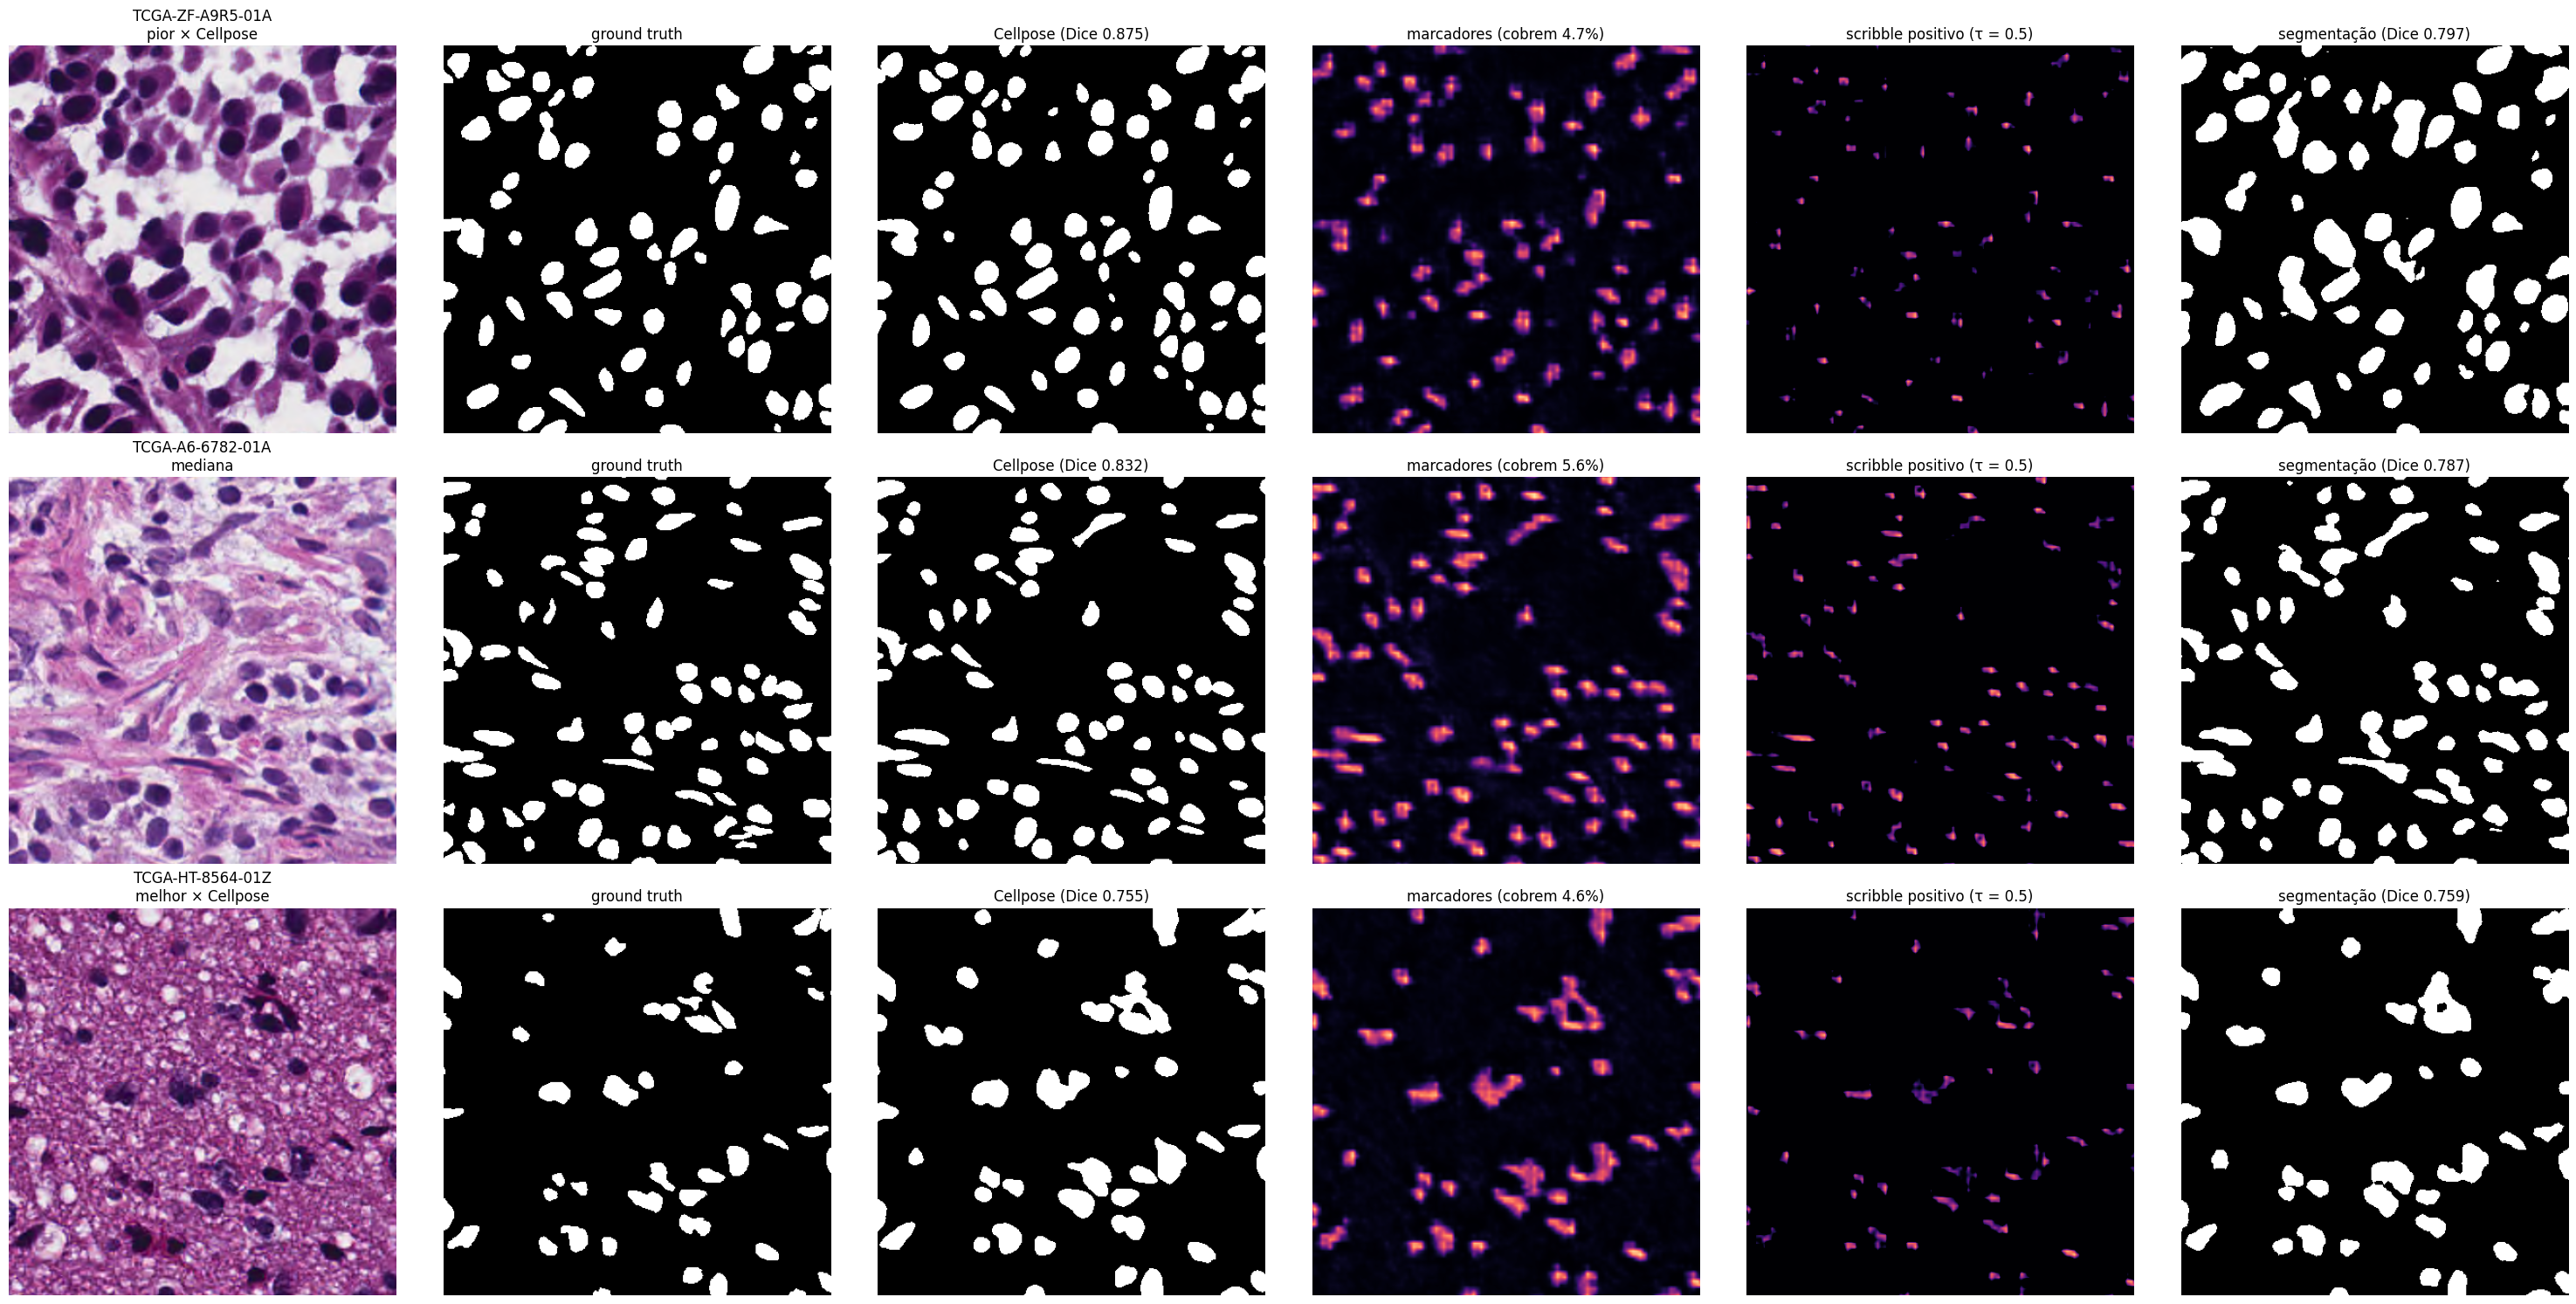

In [9]:
from src.data.load.preprocessed_dataset import PreprocessedDataset, collate_samples

RECORTE = 400  # lado do recorte central, em pixels (1000 = imagem inteira)

for step in final_pipeline.steps:
    if hasattr(step, "set_training"):
        step.set_training(False)

ordem = sorted(test_rows, key=lambda r: r["dice"] - r["cellpose_dice"])
escolhidas = [("pior × Cellpose", ordem[0]), ("mediana", ordem[len(ordem) // 2]), ("melhor × Cellpose", ordem[-1])]
c0 = (1000 - RECORTE) // 2
corte = (slice(c0, c0 + RECORTE), slice(c0, c0 + RECORTE))

fig, axes = plt.subplots(len(escolhidas), 6, figsize=(30, 5 * len(escolhidas)))
for row, (rotulo, r) in enumerate(escolhidas):
    batch = collate_samples([PreprocessedDataset(test_samples, ids=[r["id"]])[0]])
    with torch.no_grad():
        out = final_pipeline.run({k: (v.to(CONFIG.device) if torch.is_tensor(v) else v) for k, v in batch.items()},
                                 verbose=False)
    sample = test_samples[r["id"]]
    paineis = [
        (f"{r['id'][:16]}\n{rotulo}", sample["image"], None),
        ("ground truth", sample["ground_truth"], "gray"),
        (f"Cellpose (Dice {r['cellpose_dice']:.3f})", sample["cellpose_segmentation"] > 0, "gray"),
        (f"marcadores (cobrem {100 * r['marker_fraction']:.1f}%)", out["markers"][0, 0].cpu().numpy(), "magma"),
        (f"scribble positivo (τ = {TAU})",
         FINAL_NET._prepare_scribbles(out["markers"], torch.device(CONFIG.device))[0, 0].cpu().numpy(), "magma"),
        (f"segmentação (Dice {r['dice']:.3f})", out["segmentation"][0, 0].cpu().numpy() >= CONFIG.threshold, "gray"),
    ]
    for ax, (titulo, img, cmap) in zip(axes[row], paineis):
        ax.imshow(img[corte], cmap=cmap, **({} if cmap is None else {"vmin": 0, "vmax": 1}))
        ax.set_title(titulo)
        ax.axis("off")
plt.tight_layout()
fig.savefig(os.path.join(run_dir, "figura_teste.png"), dpi=80, bbox_inches="tight")
plt.show()

## 8. Curvas e comparação por imagem

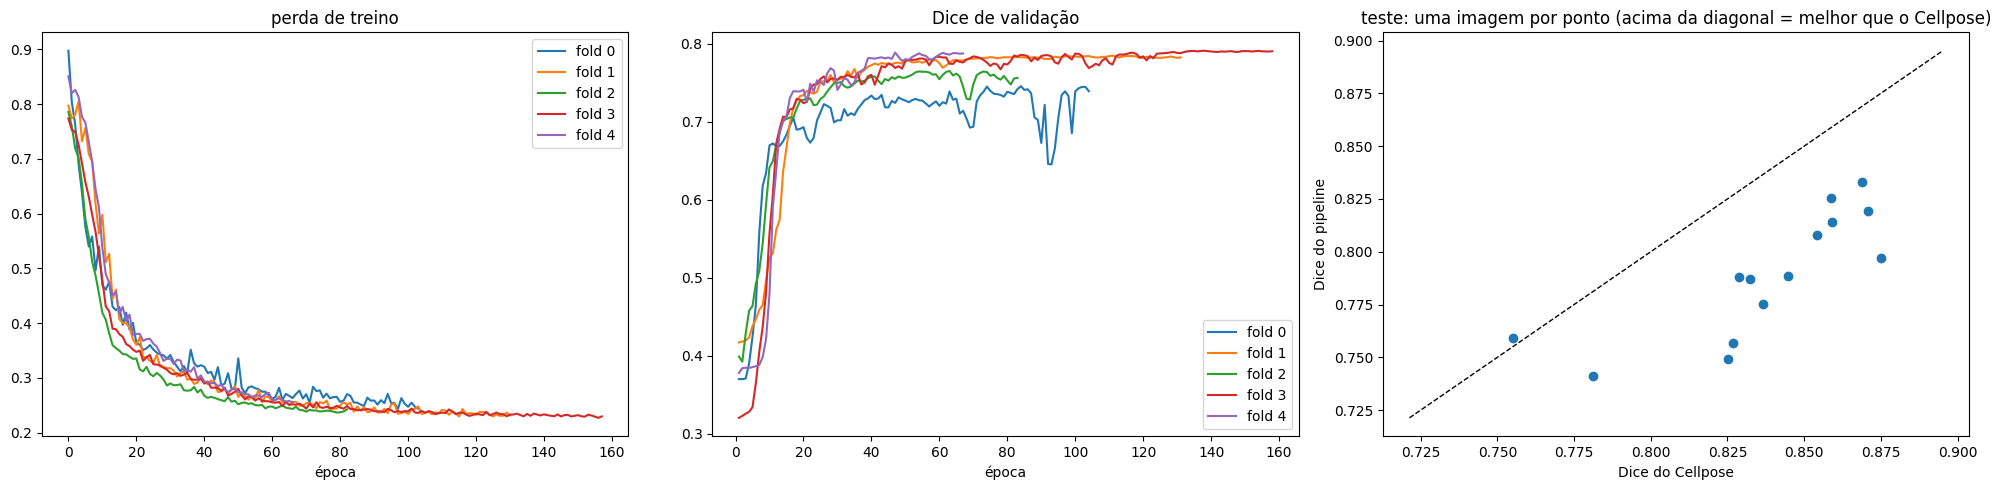

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for f in folds:
    axes[0].plot(f.train_loss_history, label=f"fold {f.fold}")
    axes[1].plot([h["epoch"] for h in f.val_dice_history], [h["dice"] for h in f.val_dice_history], label=f"fold {f.fold}")
axes[0].set_title("perda de treino")
axes[1].set_title("Dice de validação")
for ax in axes[:2]:
    ax.set_xlabel("época")
    ax.legend()

dice = np.array([r["dice"] for r in test_rows])
base = np.array([r["cellpose_dice"] for r in test_rows])
axes[2].scatter(base, dice)
lo, hi = min(dice.min(), base.min()) - 0.02, max(dice.max(), base.max()) + 0.02
axes[2].plot([lo, hi], [lo, hi], "k--", lw=1)
axes[2].set_xlabel("Dice do Cellpose")
axes[2].set_ylabel("Dice do pipeline")
axes[2].set_title("teste: uma imagem por ponto (acima da diagonal = melhor que o Cellpose)")
plt.tight_layout()
plt.show()

## 9. Baixar os resultados (Colab)

In [ ]:
if "google.colab" in sys.modules:
    import shutil

    from google.colab import files

    archive = shutil.make_archive(f"/content/{EXPERIMENT_NAME}", "zip", root_dir=run_dir)
    files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

: 